# 02 · Por dentro dos modelos de fundação: dados, tamanho, amostragem e saída estruturada

> **Capítulo 2 do livro:** *Understanding Foundation Models*.
> Este notebook segue a ordem do capítulo: dados de treino, arquitetura e tamanho, pós-treino, amostragem e saídas estruturadas. As ideias viram experimentos com texto de fábrica.

**Objetivo:** entender as escolhas por trás de um modelo de fundação que afetam quem constrói aplicações (idioma, tamanho, amostragem) e transformar a anotação livre do operador num JSON que o sistema de OEE aceita.

## Antes de começar

- **Você precisa de:** o notebook 01 (modelo de linguagem, token, temperatura).
- **Você não precisa de:** GPU nem chave de API.
- **Tempo:** 50 minutos.

## Mapa do notebook

1. Dados de treino: por que o português custa mais caro
2. Arquitetura: atenção em 15 linhas
3. Tamanho: parâmetros, memória e o que cabe na sua máquina
4. Pós-treino: de "completar texto" a "seguir instruções"
5. Amostragem: temperatura, top-k e top-p
6. Gastar mais na hora de responder: melhor de N com verificador
7. Saída estruturada: da anotação ao JSON
8. A natureza probabilística: mesma pergunta, respostas diferentes

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt
from aiind.corpus import notes
from aiind.tinylm import NGram, BPE, word_tokens

## 1. Dados de treino: o idioma tem preço

Um modelo aprende o que viu. Se ele viu muito mais inglês que português, o **tokenizador** aprende a cortar bem o inglês, e o português se quebra em pedaços menores.

Vamos simular isso: treinar um BPE com uma mistura de **90 % inglês e 10 % português** (a mesma anotação, traduzida palavra a palavra) e contar tokens das mesmas frases nos dois idiomas.

### Pare e preveja

O mesmo conteúdo em português vai gastar quantas vezes mais tokens que em inglês: 1×, 1,5×, 2× ou mais?

In [2]:
from aiind.foundation import to_english
pt = notes(2000); en = [to_english(t) for t in pt]
bpe = BPE(merges=150).fit(en[:1800] + pt[:200])          # 90 % inglês, 10 % português

teste = notes(300, seed=7)
tok_pt = sum(len(bpe.tokens(t)) for t in teste)
tok_en = sum(len(bpe.tokens(to_english(t))) for t in teste)
print(f"português: {tok_pt} tokens | inglês: {tok_en} tokens | razão {tok_pt/tok_en:.1f}x\n")
exemplo = teste[0]
print(exemplo, "->", len(bpe.tokens(exemplo)), "tokens"); print("  ", bpe.tokens(exemplo))
print(to_english(exemplo), "->", len(bpe.tokens(to_english(exemplo))), "tokens"); print("  ", bpe.tokens(to_english(exemplo)))

português: 7544 tokens | inglês: 3033 tokens | razão 2.5x

rotuladora parada sensor de etiqueta travou chamado manutenção sensor de etiqueta ajustado -> 49 tokens
   ['ro', 't', 'u', 'l', 'ad', 'ora_', 'parada_', 'sensor_', 'd', 'e_', 'e', 'ti', 'q', 'u', 'e', 't', 'a_', 't', 'ra', 'v', 'o', 'u', '_', 'ch', 'am', 'ado_', 'm', 'an', 'u', 'ten', 'ç', 'ã', 'o_', 'sensor_', 'd', 'e_', 'e', 'ti', 'q', 'u', 'e', 't', 'a_', 'a', 'j', 'u', 's', 't', 'ado_']
labeler stopped sensor label jammed called maintenance sensor label adjusted -> 16 tokens
   ['labeler_', 'stopped_', 'sensor_', 'labe', 'l_', 'jammed_', 'called_', 'maintenance_', 'sensor_', 'labe', 'l_', 'ad', 'j', 'u', 's', 'ted_']


O mesmo conteúdo custa cerca de **2,5 vezes mais tokens** em português. Palavras como `labeler` e `stopped` viraram um token só; `rotuladora` e `manutenção` ficaram picadas.

Na vida real a diferença entre idiomas é menor, porque os tokenizadores dos grandes modelos já veem bastante português, mas o efeito existe e é medido. Três consequências práticas:

- **Custo:** a API cobra por token.
- **Latência:** gerar cada token leva tempo.
- **Contexto:** o mesmo limite de tokens cabe menos texto em português.

O mesmo vale para domínio: vocabulário de fábrica (nomes de peça, códigos de falha, siglas) aparece pouco nos dados de treino. É por isso que existem **modelos de domínio**, treinados ou ajustados com texto de uma área específica.

## 2. Arquitetura: atenção em 15 linhas

No notebook 01, o trigrama só via duas palavras para trás. O **transformer**, a arquitetura dominante, resolve isso com **atenção**: para gerar cada posição, o modelo olha para **todas** as anteriores e decide quanto peso dar a cada uma.

O cálculo é curto. Cada token vira três vetores:
- **query (Q):** o que estou procurando;
- **key (K):** o que eu ofereço;
- **value (V):** o que eu entrego se for escolhido.

O peso de cada token anterior sai do produto Q·K, passado por um softmax. A máscara **causal** impede de olhar para o futuro, porque na hora de gerar o futuro ainda não existe.

Abaixo os vetores são escolhidos à mão, para o efeito ficar visível: o token `vazando` "procura" uma peça, e a `vedação` "oferece" ser uma peça.

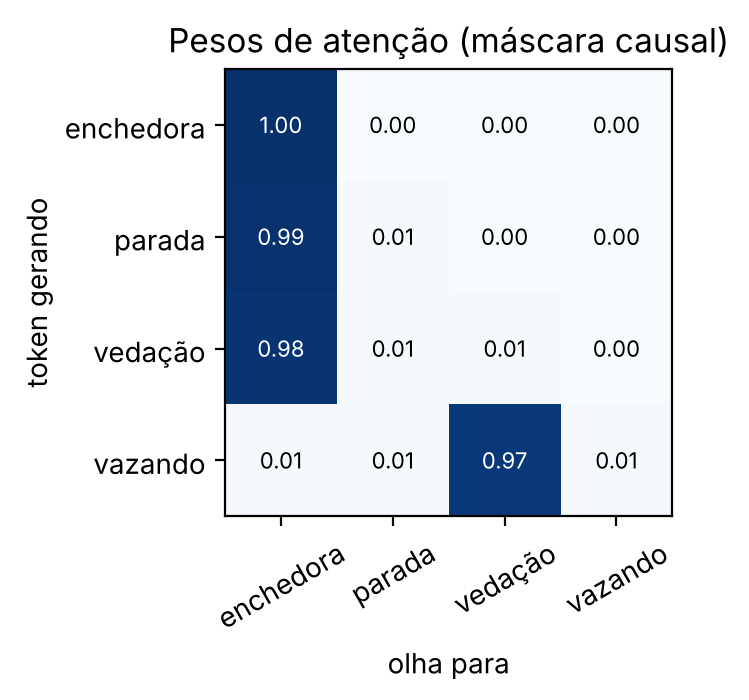

In [3]:
import numpy as np
from aiind.foundation import attention
frase = ["enchedora", "parada", "vedação", "vazando"]
# dimensões dos vetores: [é máquina, é estado, é peça, é sintoma]
K = np.array([[3,0,0,0], [0,3,0,0], [0,0,3,0], [0,0,0,3]], float)
Q = np.array([[0,0,0,0],     # enchedora: não procura nada em especial
              [3,0,0,0],     # parada: procura qual máquina
              [3,0,0,0],     # vedação: procura de qual máquina
              [0,0,3,0]], float)  # vazando: procura qual peça
V = np.eye(4)
saida, pesos = attention(Q, K, V, causal=True)

fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.imshow(pesos, cmap="Blues")
ax.set_xticks(range(4), frase, rotation=30); ax.set_yticks(range(4), frase)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{pesos[i,j]:.2f}", ha="center", va="center", fontsize=8, color="white" if pesos[i,j] > .5 else "black")
ax.set_xlabel("olha para"); ax.set_ylabel("token gerando"); ax.set_title("Pesos de atenção (máscara causal)")
plt.tight_layout()

Leia por linha:

- `vazando` põe quase todo o peso em `vedação`: achou a peça que vaza.
- `parada` olha para `enchedora`.
- A metade de cima à direita é zero: é a máscara causal.

Num modelo real, Q, K e V não são escritos à mão: saem de matrizes **aprendidas** no treino. O modelo também tem dezenas de "cabeças" de atenção em paralelo e dezenas de camadas empilhadas. Mas a conta de cada cabeça é exatamente esta.

O custo dessa conta cresce com o **quadrado** do comprimento do contexto: cada token olha para todos os anteriores. É por isso que contexto longo é caro, e o capítulo 9 volta a esse ponto.

## 3. Tamanho: quanto pesa um modelo

O tamanho de um modelo é dado em **parâmetros**, os números aprendidos. Uma conta aproximada para um transformer: cada camada tem cerca de 12·d² parâmetros (d é a largura do modelo), mais a tabela de embeddings, vocabulário × d.

In [4]:
from aiind.foundation import transformer_params, weights_gb
configs = {   # camadas, largura, vocabulário: configurações típicas de três ordens de grandeza
    "pequeno": (24,  896, 150_000),
    "médio":   (32, 4096, 128_000),
    "grande":  (80, 8192, 128_000),
}
print(f"{'modelo':8s} {'parâmetros':>12s} {'FP32':>9s} {'FP16':>9s} {'INT8':>9s} {'INT4':>9s}   (GB só para os pesos)")
for nome, (L, d, V) in configs.items():
    p = transformer_params(L, d, V)
    print(f"{nome:8s} {p/1e9:10.2f} B " + " ".join(f"{weights_gb(p, b):8.1f}" for b in (32, 16, 8, 4)))

modelo     parâmetros      FP32      FP16      INT8      INT4   (GB só para os pesos)
pequeno        0.37 B      1.5      0.7      0.4      0.2
médio          6.97 B     27.9     13.9      7.0      3.5
grande        65.47 B    261.9    130.9     65.5     32.7


### Pare e preveja

Um servidor de borda na fábrica tem 16 GB de memória para o modelo. Qual desses modelos cabe, e em qual precisão?

A tabela responde: o pequeno cabe em qualquer precisão; o médio só a partir de FP16 (justo) ou INT8; o grande não cabe nem em 4 bits. E isso é **só para os pesos**: rodar o modelo ainda gasta memória com o contexto (o "cache KV", capítulo 9).

Daí uma decisão comum na indústria: **modelo grande na nuvem** para tarefas difíceis, ou **modelo pequeno local** quando o dado não pode sair da rede OT. Reduzir de 16 para 4 bits por parâmetro (**quantização**) é o que torna o modelo local viável. O capítulo 7 faz essa conta em detalhe.

Mais parâmetros só ajudam se houver dados suficientes para treiná-los. A pesquisa sobre leis de escala mostrou que o treino eficiente usa muito mais tokens de treino do que parâmetros (dezenas de tokens por parâmetro). Por isso o preço de um modelo não está só no tamanho: está em **quanto dado e quanta computação** foram gastos nele.

## 4. Pós-treino: de completar texto a seguir instruções

Um modelo que só passou pelo pré-treino faz uma coisa: **continua texto**. Pergunte "Qual a causa da parada?" e ele pode responder com outra pergunta, porque em muitos textos perguntas vêm em lista.

O pós-treino tem duas etapas:

| Etapa | O que o modelo vê | O que ele aprende |
|---|---|---|
| **Ajuste supervisionado (SFT)** | exemplos de instrução e resposta boa, escritos por pessoas | o formato de "conversa": pergunta, resposta |
| **Ajuste por preferência** | duas respostas para a mesma pergunta e qual foi preferida | a responder do jeito que as pessoas preferem |

Na prática: o SFT ensina **o que** fazer; a preferência ensina **qual de duas respostas plausíveis** é melhor. Para a preferência, treina-se um **modelo de recompensa** que dá nota a respostas, e o modelo principal aprende a buscar notas altas.

O nosso trigrama não tem pós-treino, mas dá para mostrar a peça central dele, o **verificador**: uma função que dá nota a uma saída. Abaixo, um verificador para anotações geradas: a máquina existe, só cita peças dela e a frase não se perde.

In [5]:
from aiind.structured import coherent_note
from aiind.sampling import generate
tri = NGram(order=3).fit([word_tokens(t) for t in notes(2000)])
rng = random.Random(5)
geradas = [" ".join(generate(tri, rng, temperature=1.0)[0]) for _ in range(500)]
print(f"anotações geradas aprovadas pelo verificador: {sum(map(coherent_note, geradas))/500:.0%}\n")
for t in geradas[:6]:
    print("OK " if coherent_note(t) else "-- ", t)

anotações geradas aprovadas pelo verificador: 67%

--  rotuladora parada faca aquecendo chamado manutenção cortina de luz recalibrado palete etiqueta luz leitura reapertado falta bico matriz desalinhado chamado manutenção
OK  enchedora voltou a operar
--  prensa parada matriz aquecendo chamado líder vedação recalibrado
OK  tampadora parada falta de operador
OK  paletizadora voltou a operar
OK  rotuladora troca de turno


Só cerca de dois terços passam. Os erros mais comuns são peças de outra máquina e frases que não terminam, efeito direto do contexto curto.

## 5. Amostragem: o modelo dá as probabilidades, você decide o que fazer com elas

O modelo calcula uma distribuição para o próximo token. A **estratégia de amostragem** decide o que fazer com ela:

| Estratégia | O que faz | Efeito |
|---|---|---|
| gulosa (temperatura 0) | sempre o mais provável | repetitivo, determinístico |
| temperatura | achata (>1) ou afia (<1) a distribuição | mais ou menos variedade |
| top-k | só sorteia entre os k mais prováveis | corta a cauda longa de absurdos |
| top-p (núcleo) | só entre os mais prováveis que somam p | como top-k, mas adapta o corte |

Vejamos a distribuição depois de `"enchedora parada"`, e o que cada estratégia faz com ela:

tokens em ordem: ['falta', 'bico', 'válvula', 'vedação', 'sensor', 'para'] ...


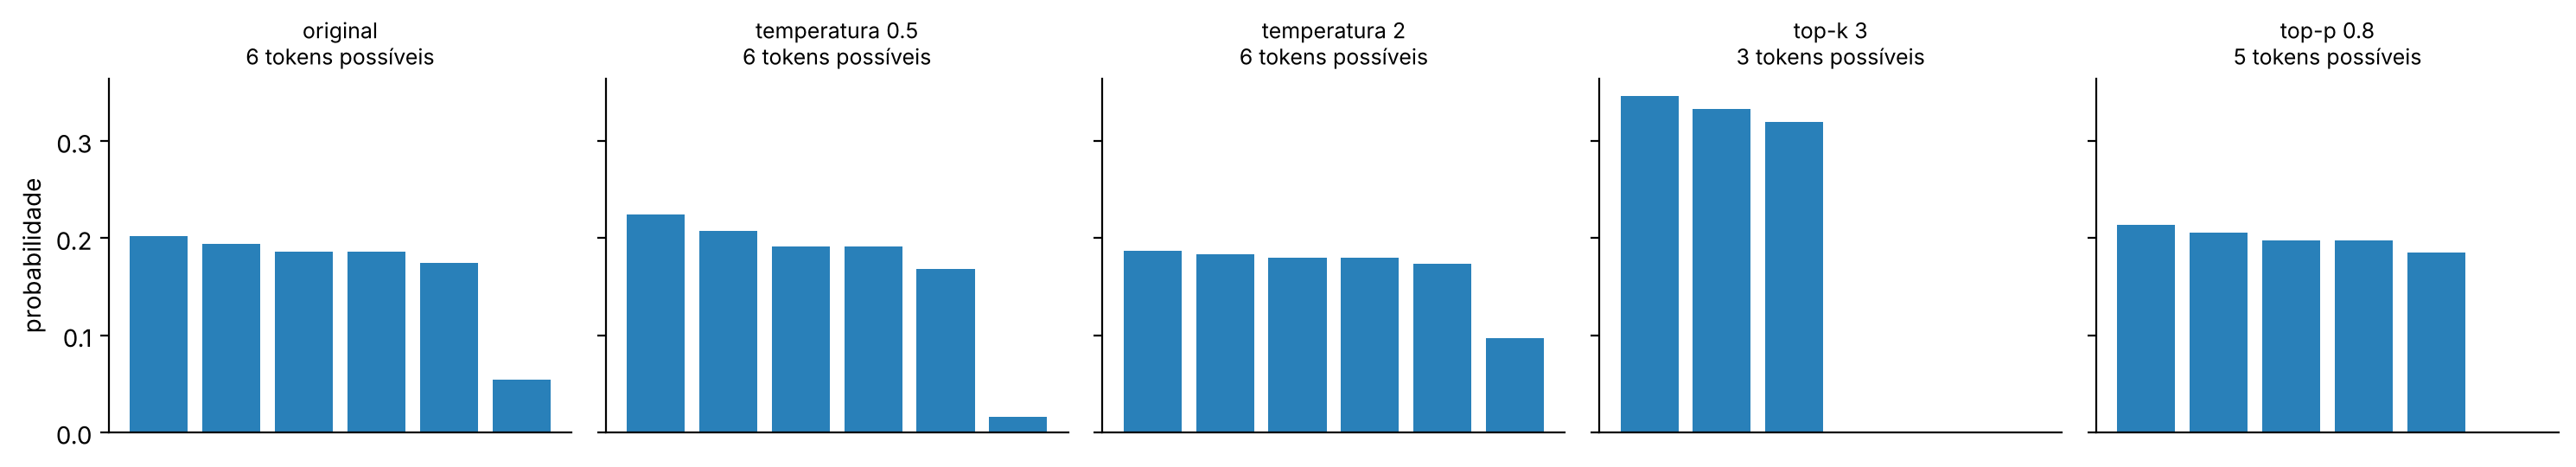

In [6]:
from aiind.sampling import apply_temperature, top_k, top_p
dist = {k: v for k, v in tri.next_probs(["enchedora", "parada"]).items() if v > 0.001}
versoes = {"original": dist, "temperatura 0.5": apply_temperature(dist, .5), "temperatura 2": apply_temperature(dist, 2),
           "top-k 3": top_k(dist, 3), "top-p 0.8": top_p(dist, .8)}
fig, axes = plt.subplots(1, 5, figsize=(15, 2.8), sharey=True)
ordem = sorted(dist, key=dist.get, reverse=True)
for ax, (nome, d) in zip(axes, versoes.items()):
    ax.bar(range(len(ordem)), [d.get(t, 0) for t in ordem], color="#2980b9")
    ax.set_title(f"{nome}\n{sum(1 for t in ordem if d.get(t, 0) > 0.001)} tokens possíveis", fontsize=9)
    ax.set_xticks([]); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("probabilidade"); plt.tight_layout()
print("tokens em ordem:", ordem[:8], "...")

### Pare e preveja

Qual estratégia gera **mais** anotações aprovadas pelo verificador: temperatura 1, temperatura 0.5, top-k 3 ou top-p 0.8? E qual gera **mais variedade** (anotações diferentes entre si)?

In [7]:
estrategias = {"temperatura 1": dict(temperature=1.0), "temperatura 0.5": dict(temperature=0.5),
               "top-k 3": dict(temperature=1.0, k=3), "top-p 0.8": dict(temperature=1.0, p=0.8),
               "gulosa (temp. 0)": dict(temperature=0)}
for nome, kw in estrategias.items():
    rng = random.Random(1)
    g = [" ".join(generate(tri, rng, **kw)[0]) for _ in range(300)]
    print(f"{nome:18s} aprovadas {sum(map(coherent_note, g))/300:5.0%}   distintas {len(set(g)):3d} de 300")

temperatura 1      aprovadas   68%   distintas 228 de 300


temperatura 0.5    aprovadas   79%   distintas 238 de 300
top-k 3            aprovadas   92%   distintas 129 de 300


top-p 0.8          aprovadas   71%   distintas 238 de 300
gulosa (temp. 0)   aprovadas  100%   distintas   1 de 300


A troca aparece nos números: **cortar a cauda aumenta a qualidade e reduz a variedade**. A gulosa é perfeita e inútil para gerar dados, porque repete a mesma frase. Na prática:

- **Extrair dados, classificar, responder com fato:** temperatura baixa (0 a 0,3).
- **Gerar ideias, variações, dados sintéticos:** temperatura mais alta, com top-p para cortar absurdos.

## 6. Gastar mais na hora de responder: melhor de N

Outra forma de melhorar a saída sem trocar o modelo: **gerar várias respostas e escolher a melhor** com um verificador. Isso troca computação na hora da resposta por qualidade.

### Pare e preveja

Se 1 amostra é aprovada em ~67 % das vezes, com quantas amostras a chance de **ao menos uma** ser aprovada passa de 95 %?

N = 1: ao menos uma aprovada em 63% das vezes


N = 2: ao menos uma aprovada em 91% das vezes
N = 3: ao menos uma aprovada em 98% das vezes


N = 4: ao menos uma aprovada em 100% das vezes
N = 8: ao menos uma aprovada em 100% das vezes


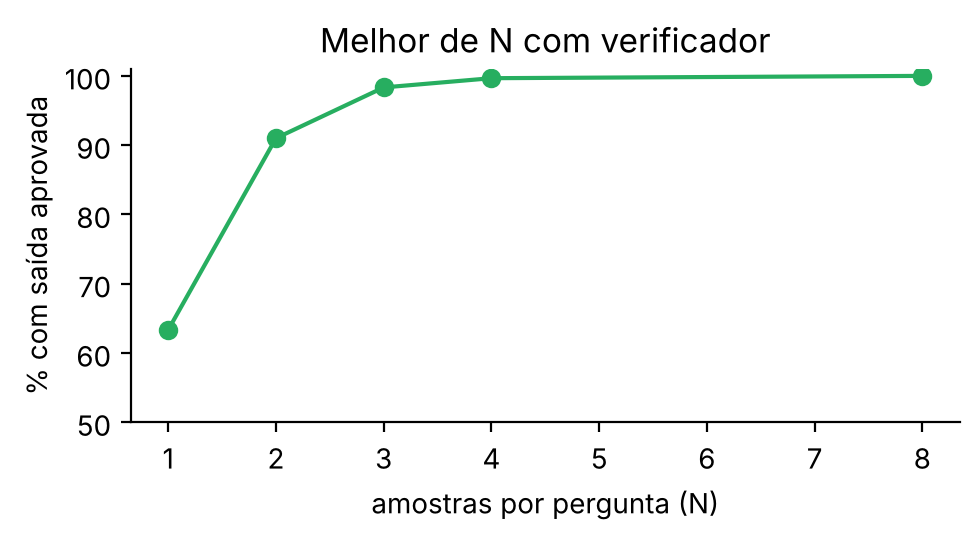

In [8]:
Ns, taxa = [1, 2, 3, 4, 8], []
rng = random.Random(9)
for N in Ns:
    ok = sum(any(coherent_note(" ".join(generate(tri, rng)[0])) for _ in range(N)) for _ in range(300))
    taxa.append(ok / 300)
    print(f"N = {N}: ao menos uma aprovada em {ok/300:.0%} das vezes")
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(Ns, [100 * t for t in taxa], "o-", color="#27ae60"); ax.set_xlabel("amostras por pergunta (N)")
ax.set_ylabel("% com saída aprovada"); ax.set_ylim(50, 101); ax.set_title("Melhor de N com verificador")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()

Com 3 amostras já passa de 95 %. Se cada tentativa é independente, a falha cai como 0,33 elevado a N.

O custo é óbvio: **N vezes mais tokens e mais tempo**. E tudo depende do verificador: se ele aprova saídas erradas, gerar mais só escolhe o erro com mais confiança. Na indústria, os melhores verificadores são **regras do domínio**: a peça pertence à máquina? O valor está dentro do limite? O código de falha existe no CMMS?

## 7. Saída estruturada: da anotação ao JSON

Agora a tarefa que interessa ao sistema de OEE:

```
"enchedora parada vedação vazando chamado manutenção"
  -> {"maquina": "enchedora", "peca": "vedação", "problema": "vazando", "categoria": "falha"}
```

Treinamos o trigrama com 3.000 linhas no formato `anotação => JSON` e comparamos três jeitos de obter o JSON:

1. **Pedir e torcer:** gerar livremente e tentar ler o JSON.
2. **Validar e repetir:** se não validar, gerar de novo (até 3 vezes).
3. **Decodificação restrita:** a cada passo, só os tokens que o esquema permite podem ser sorteados. A peça só pode ser uma peça **daquela** máquina.

### Pare e preveja

Com decodificação restrita, que porcentagem dos JSONs será válida? E que porcentagem estará **correta** (igual ao que uma pessoa extrairia)?

In [9]:
from aiind.structured import labeled, training_sequences, schema_allowed, parse, valid, FIELDS, SEP, rule_extract
dados_tr, dados_te = labeled(3000), labeled(200, seed=7)
extrator = NGram(order=3).fit(training_sequences(dados_tr))

def avaliar(restrito=False, tentativas=1, temperatura=1.0):
    rng = random.Random(0); validos = corretos = campos = 0
    for nota, certo in dados_te:
        prompt = nota.split() + [SEP]
        for _ in range(tentativas):
            toks, _ = generate(extrator, rng, temperature=temperatura, prompt=prompt, max_len=len(prompt) + 16,
                               allowed=schema_allowed(len(prompt)) if restrito else None)
            rec = parse(toks[len(prompt):])
            if not valid(rec):
                break
        if not valid(rec):
            validos += 1; corretos += rec == certo; campos += sum(rec[f] == certo[f] for f in FIELDS)
    n = len(dados_te)
    return validos / n, corretos / n, campos / (4 * n)

res = {"pedir e torcer": avaliar(), "validar e repetir (3x)": avaliar(tentativas=3),
       "decodificação restrita": avaliar(restrito=True), "restrita, temperatura 0": avaliar(restrito=True, temperatura=0)}
print(f"{'estratégia':26s} {'JSON válido':>12s} {'registro correto':>17s} {'campos corretos':>16s}")
for k, (v, c, f) in res.items():
    print(f"{k:26s} {v:12.0%} {c:17.0%} {f:16.0%}")
rng = random.Random(3); nota, certo = dados_te[0]; prompt = nota.split() + [SEP]
toks, _ = generate(extrator, rng, prompt=prompt, max_len=len(prompt) + 16, allowed=schema_allowed(len(prompt)))
print("\nanotação:", nota); print("gerado:  ", parse(toks[len(prompt):])); print("correto: ", certo)

estratégia                  JSON válido  registro correto  campos corretos
pedir e torcer                      29%                0%               8%
validar e repetir (3x)              67%                0%              17%
decodificação restrita             100%                0%              30%
restrita, temperatura 0            100%                0%              40%

anotação: rotuladora parada sensor de etiqueta travou chamado manutenção sensor de etiqueta ajustado
gerado:   {'maquina': 'prensa', 'peca': 'matriz', 'problema': 'nenhum', 'categoria': 'falha'}
correto:  {'maquina': 'rotuladora', 'peca': 'sensor de etiqueta', 'problema': 'travou', 'categoria': 'falha'}


Este é o resultado mais importante do notebook:

- A decodificação restrita deu **100 % de JSON válido**, sempre, e nenhuma peça de máquina errada. O esquema virou garantia.
- Mas quase **nenhum registro está correto**. O trigrama vê só as duas últimas palavras (`... manutenção =>`) e não "lê" a anotação: inventa a máquina.

> **Estrutura não é correção.** A decodificação restrita garante o formato; quem garante o conteúdo é a capacidade do modelo de entender o texto, e é isso que um modelo grande traz.

Antes de culpar o modelo, vale um teste que todo projeto deveria fazer: **uma linha de base simples**. Um extrator por dicionário, sem IA nenhuma:

In [10]:
acertos = [rule_extract(n) == c for n, c in dados_te]
print(f"extrator por regras: {sum(acertos)/len(acertos):.1%} dos registros corretos\n")
for (n, c), ok in zip(dados_te, acertos):
    if not ok:
        print("errou em:", n); print("   regras: ", rule_extract(n)); print("   correto:", c)

extrator por regras: 99.5% dos registros corretos

errou em: tampadora parada falta de garrafa
   regras:  {'maquina': 'tampadora', 'peca': 'garra', 'problema': 'nenhum', 'categoria': 'falta'}
   correto: {'maquina': 'tampadora', 'peca': 'nenhum', 'problema': 'nenhum', 'categoria': 'falta'}


As regras acertam 99,5 %, e o único erro é instrutivo: em "falta de **garra**fa", a regra achou a peça "garra" dentro da palavra "garrafa". Regras quebram em casos assim, e anotação real é cheia de abreviação, erro de digitação e gíria da linha ("enchedora deu pau no bico").

A arquitetura que costuma funcionar na fábrica combina os dois:

1. **Regras** para o que é fixo e verificável (lista de máquinas, peças, códigos).
2. **Modelo grande** para ler texto bagunçado.
3. **Saída estruturada com esquema** para o modelo nunca devolver um formato quebrado.
4. **Validação de domínio** no final: a peça pertence à máquina? Se não, o registro volta para revisão.

O capítulo 6 (RAG e agentes) faz isso com um modelo de verdade.

## 8. A natureza probabilística

A mesma pergunta, feita várias vezes, pode ter respostas diferentes. Veja o extrator respondendo 8 vezes sobre a mesma anotação:

In [11]:
nota, certo = dados_te[5]; prompt = nota.split() + [SEP]
print("anotação:", nota, "\n")
for semente in range(8):
    toks, logp = generate(extrator, random.Random(semente), prompt=prompt, max_len=len(prompt) + 16, allowed=schema_allowed(len(prompt)))
    r = parse(toks[len(prompt):])
    print(f"log-prob {logp:7.2f}  {r['maquina']:12s} {r['peca']:20s} {r['problema']:12s} {r['categoria']}")

anotação: paletizadora parada filme sem leitura filme recalibrado 

log-prob   -6.51  prensa       nenhum               com ruído    falha
log-prob   -5.42  enchedora    nenhum               nenhum       falha
log-prob   -8.91  rotuladora   nenhum               vazando      retorno
log-prob   -7.57  prensa       matriz               nenhum       falha
log-prob   -6.43  prensa       nenhum               aquecendo    falha
log-prob  -10.01  enchedora    válvula              desalinhado  falta
log-prob   -6.19  prensa       nenhum               nenhum       planejada
log-prob   -6.75  tampadora    nenhum               nenhum       falta


Duas propriedades que acompanham todo modelo de linguagem, grande ou pequeno:

- **Inconsistência:** respostas diferentes para a mesma entrada. Mitigações: temperatura 0, semente fixa quando a API permite, e cache de respostas.
- **Alucinação:** resposta bem formada e sem base no que foi dado. Aqui, o extrator "vê" peças que não estão na anotação. Mitigações: dar o contexto certo (capítulo 6), validar contra a realidade e medir.

A coluna **log-prob** é a confiança do próprio modelo na sequência que gerou. Muitas APIs devolvem esse valor, e ele ajuda a decidir quando mandar uma resposta para revisão humana. Só não confunda confiança com acerto: um modelo pode estar muito confiante e errado.

## Erros comuns

- **Ignorar o idioma no orçamento.** O mesmo texto em português gasta mais tokens.
- **Escolher o maior modelo por padrão.** Primeiro veja onde ele vai rodar e quanto custa por chamada.
- **Usar temperatura alta para extrair dados.** Extração quer temperatura baixa.
- **Confiar que JSON válido é JSON certo.** Valide o conteúdo contra as regras do domínio.
- **Pular a linha de base.** Se regras acertam 99 %, a IA precisa justificar o custo no 1 % restante.
- **Melhor de N sem verificador bom.** Gerar mais só ajuda se a escolha for confiável.

## Confira o que ficou

**1. Por que um texto em português pode gastar mais tokens que o mesmo texto em inglês?**

<details><summary>Ver resposta</summary>

Porque o tokenizador foi treinado com mais inglês: palavras inglesas viram um token, palavras em português se quebram em vários.

</details>

**2. O que a máscara causal faz na atenção?**

<details><summary>Ver resposta</summary>

Impede cada token de olhar para os tokens seguintes, porque na geração o futuro ainda não existe.

</details>

**3. Um modelo de 7 bilhões de parâmetros em 4 bits ocupa cerca de quanto só nos pesos?**

<details><summary>Ver resposta</summary>

Cerca de 3,5 GB (7e9 × 4 bits ÷ 8).

</details>

**4. Qual a diferença entre ajuste supervisionado e ajuste por preferência?**

<details><summary>Ver resposta</summary>

O supervisionado aprende com exemplos de respostas boas; o de preferência aprende qual de duas respostas plausíveis as pessoas preferem.

</details>

**5. Top-k e top-p fazem o quê com a distribuição?**

<details><summary>Ver resposta</summary>

Descartam os tokens menos prováveis antes de sortear. O top-k mantém um número fixo; o top-p mantém os que somam a probabilidade p.

</details>

**6. A decodificação restrita deu 100 % de JSON válido e quase 0 % de registros corretos. Por quê?**

<details><summary>Ver resposta</summary>

Ela garante o formato, não o conteúdo. O trigrama não consegue ler a anotação inteira para escolher os valores certos.

</details>

**7. Melhor de N depende de quê para funcionar?**

<details><summary>Ver resposta</summary>

De um verificador confiável e de as tentativas serem independentes. E custa N vezes mais.

</details>

## Exercícios

1. **Idioma:** mude a mistura do BPE para 50 % e 50 % e recalcule a razão de tokens. O que acontece? E com 100 % português?
2. **Atenção:** edite a matriz Q para que `vedação` procure um sintoma em vez de uma máquina. O que muda na linha dela? Por que ela não consegue olhar para `vazando`?
3. **Memória:** quantos parâmetros cabem em 8 GB em INT4? E em FP16?
4. **Amostragem:** encontre a temperatura que maximiza "aprovadas × distintas" para gerar dados sintéticos.
5. **Regras:** corrija o extrator por regras para não achar "garra" dentro de "garrafa" (dica: compare palavras inteiras) e rode de novo.
6. **Esquema:** acrescente ao esquema o campo `acao` (ajustado, trocado...) com o valor `nenhum` permitido, e atualize `schema_allowed`.

## Glossário

- **Modelo de domínio:** modelo treinado ou ajustado com texto de uma área específica.
- **Transformer:** arquitetura baseada em atenção, base dos modelos de linguagem atuais.
- **Atenção:** mecanismo em que cada token pondera todos os anteriores para decidir o que gerar.
- **Parâmetro:** número aprendido no treino; o tamanho do modelo.
- **Quantização:** guardar os parâmetros com menos bits para caber em menos memória.
- **SFT:** ajuste supervisionado com exemplos de instrução e resposta.
- **Modelo de recompensa:** modelo que dá nota a respostas, usado no ajuste por preferência.
- **Top-k, top-p:** estratégias que cortam os tokens improváveis antes do sorteio.
- **Decodificação restrita:** amostragem em que só os tokens permitidos pelo esquema podem sair.
- **Alucinação:** resposta bem formada e sem base nos dados fornecidos.

## Próximo passo

**Notebook 03, capítulo 3 (Evaluation Methodology):** como medir se um modelo é bom. Entropia, perplexidade, similaridade com embeddings e IA como juiz, aplicados a textos de manutenção.